# Plotting
## Caption: Frequency Response of the physical twin and the deterministic computational model.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.linalg import eigvals

# Parameters

In [2]:

rho = 7850  # kg/m^3
A = 4e-4  # m^2
E = 210e9  # Pa
L = 1.0  # m
N = 40  # Number of elements for physical twin
Le = L / N  # Element length
m = 0.3925  # kg (for computational model)
k = 4914e5  # N/m (for computational model)
force_magnitude = 10e3  # N
sigma_noise = 5e-4  # m
freq_range = np.linspace(1000, 8000, 701)  # Hz,
omega_range = 2 * np.pi * freq_range  # rad/s

# Physical Twin: Assemble mass and stiffness matrices

In [18]:
n_dof_pt = N + 1  # 41 DOFs
M_pt = np.zeros((n_dof_pt, n_dof_pt))
K_pt = np.zeros((n_dof_pt, n_dof_pt))
print(K_pt)

[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]


# Elementary matrices

In [4]:
Me = rho * A * Le * np.array([[1/3, 1/6], [1/6, 1/3]])
Ke = E * A / Le * np.array([[1, -1], [-1, 1]])

# Assemble global matrices

In [5]:
for i in range(N):
    M_pt[i:i+2, i:i+2] += Me
    K_pt[i:i+2, i:i+2] += Ke

# Apply fixed boundary condition (u_1 = 0)
M_pt = M_pt[1:, 1:]
K_pt = K_pt[1:, 1:]
n_dof_pt -= 1  # Now 40 DOFs

# Compute natural frequencies to validate
eigvals_pt = eigvals(K_pt, M_pt)
freqs_pt = np.sort(np.sqrt(np.abs(eigvals_pt)) / (2 * np.pi))
print("Physical Twin Natural Frequencies (Hz):", freqs_pt[:3])

Physical Twin Natural Frequencies (Hz): [1293.131625   3881.38930107 6475.63327841]


# Adjust damping

In [6]:
omega_1 = 2 * np.pi * freqs_pt[0]  # First natural frequency (rad/s)
#zeta_1 = 0.063  # First damping ratio
alpha_0 = 1e3  # Dominant for first mode
beta_0 = 1e-7  # Small to avoid over-damping higher modes
C_pt = alpha_0 * M_pt + beta_0 * K_pt

# Force vector (physical Twin)

In [7]:

f_pt = np.zeros(n_dof_pt)
f_pt[-1] = force_magnitude

# Compute FRF for physical twin
u_pt = np.zeros((n_dof_pt, len(omega_range)), dtype=complex)
for i, omega in enumerate(omega_range):
    H = np.linalg.inv(-omega**2 * M_pt + 1j * omega * C_pt + K_pt)
    u_pt[:, i] = H @ f_pt

# Add Gaussian noise to the magnitude with relative scaling
u_pt_mag = np.abs(u_pt[-1, :])
noise_scale = sigma_noise * (u_pt_mag / np.max(u_pt_mag))  # Scale noise with amplitude
noise = np.random.normal(0, noise_scale, u_pt_mag.shape)
u_pt_noisy = u_pt_mag + noise
u_pt_noisy = np.maximum(u_pt_noisy, 1e-12)  # Avoid negative or zero for log scale

# Computational Model: Define mass and stiffness matrices

In [8]:

n_dof_cm = 6
M_cm = m * np.eye(n_dof_cm)
K_cm = k * np.array([
    [2, -1, 0, 0, 0, 0],
    [-1, 2, -1, 0, 0, 0],
    [0, -1, 2, -1, 0, 0],
    [0, 0, -1, 2, -1, 0],

    [0, 0, 0, -1, 2, -1],
    [0, 0, 0, 0, -1, 1]
])
C_cm = alpha_0 * M_cm + beta_0 * K_cm

# Compute natural frequencies
eigvals_cm = eigvals(K_cm, M_cm)
freqs_cm = np.sort(np.sqrt(np.abs(eigvals_cm)) / (2 * np.pi))
print("Computational Model Natural Frequencies (Hz):", freqs_cm[:3])

Computational Model Natural Frequencies (Hz): [1357.5852134  3993.85772223 6398.02173733]


# Force vector (Computational Model)

In [9]:

f_cm = np.zeros(n_dof_cm)
f_cm[-1] = force_magnitude

# Compute FRF for computational model
u_cm = np.zeros((n_dof_cm, len(omega_range)), dtype=complex)
for i, omega in enumerate(omega_range):
    H = np.linalg.inv(-omega**2 * M_cm + 1j * omega * C_cm + K_cm)
    u_cm[:, i] = H @ f_cm

# Stochastic Computational Model

In [10]:
n_simulations = 500
m_nominal = 0.3925  # kg
k_nominal = 4914e5  # N/m
all_responses_cm = np.zeros((n_simulations, len(omega_range)))

print(f"Running {n_simulations} Monte Carlo simulations for the stochastic model...")

for sim in range(n_simulations):
    # Sample m and k from a uniform distribution +/- 5%
    m = m_nominal * np.random.uniform(0.95, 1.05)
    k = k_nominal * np.random.uniform(0.95, 1.05)

    # Assemble stochastic matrices for this simulation
    M_cm = m * np.eye(n_dof_cm)
    K_cm_base = np.array([
        [2, -1, 0, 0, 0, 0], [-1, 2, -1, 0, 0, 0],
        [0, -1, 2, -1, 0, 0], [0, 0, -1, 2, -1, 0],
        [0, 0, 0, -1, 2, -1], [0, 0, 0, 0, -1, 1]
    ])
    K_cm = k * K_cm_base
    C_cm = alpha_0 * M_cm + beta_0 * K_cm

    # Force vector
    f_cm = np.zeros(n_dof_cm)
    f_cm[-1] = force_magnitude

    # Compute FRF for this single stochastic realization
    u_cm_temp = np.zeros(len(omega_range), dtype=complex)
    for i, omega in enumerate(omega_range):
        H = np.linalg.inv(-omega**2 * M_cm + 1j * omega * C_cm + K_cm)
        u_cm_temp[i] = (H @ f_cm)[-1] # Get response of last DOF

    all_responses_cm[sim, :] = np.abs(u_cm_temp)

print("Simulations complete. Calculating statistical envelope.")

Running 500 Monte Carlo simulations for the stochastic model...
Simulations complete. Calculating statistical envelope.


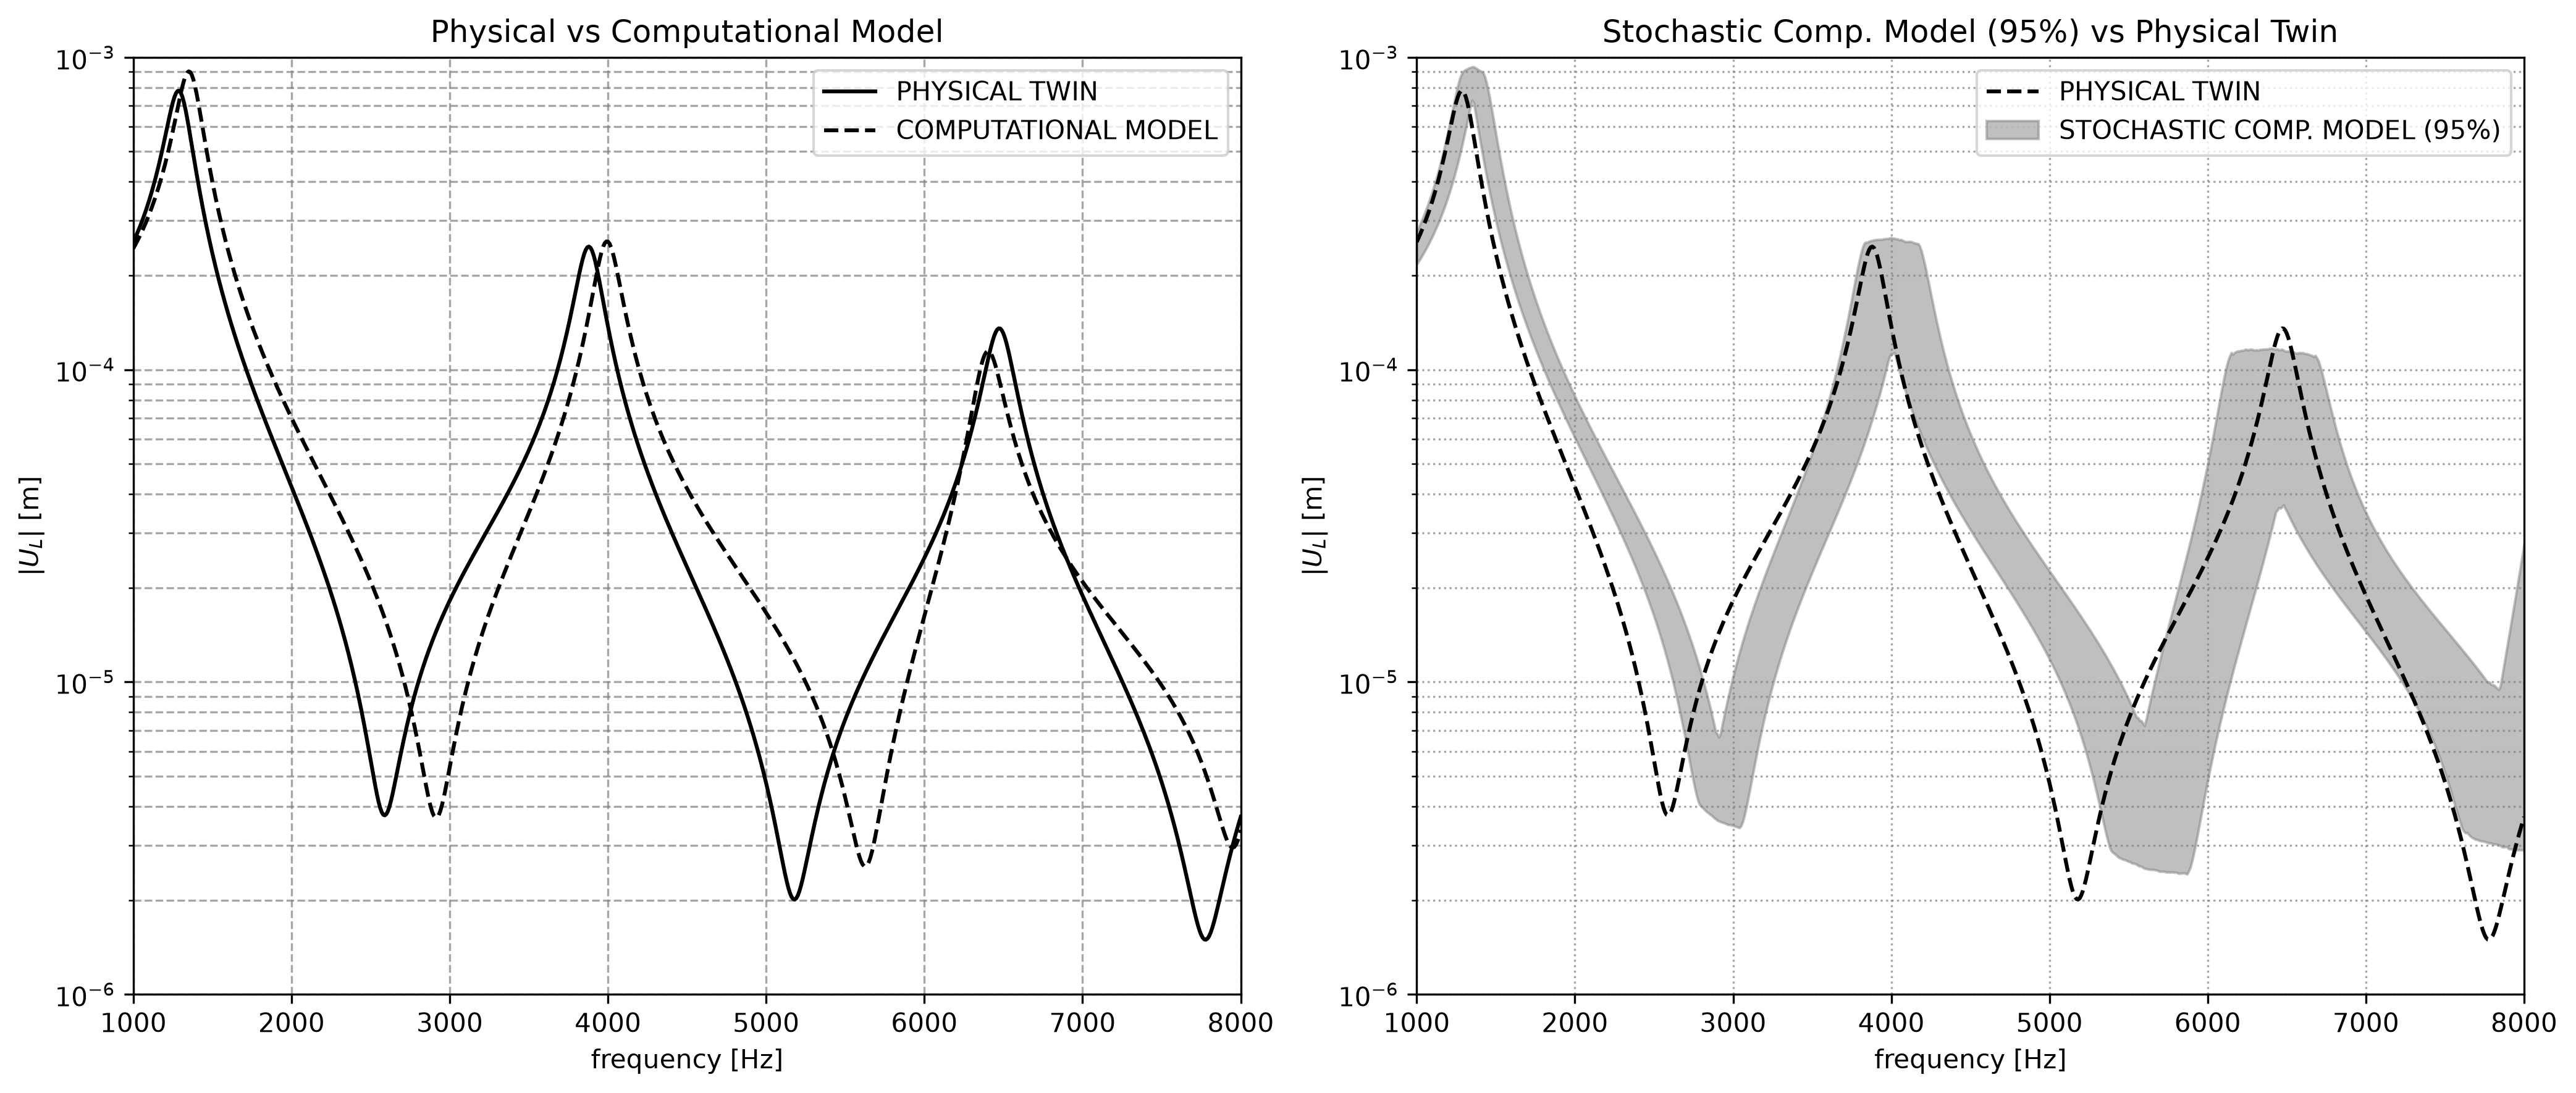

In [11]:
fig, axs = plt.subplots(1,2, figsize=(14, 6), dpi=300)

# Physical Twin vs Computational Model
axs[0].semilogy(freq_range, np.abs(u_pt[-1, :]), '-', label='PHYSICAL TWIN',
                linewidth=1.5, color='black')
axs[0].semilogy(freq_range, np.abs(u_cm[-1, :]), '--', label='COMPUTATIONAL MODEL',
                linewidth=1.5, color='black')

axs[0].set_xlabel('frequency [Hz]')
axs[0].set_ylabel(r'$|U_L|$ [m]')
axs[0].legend()
axs[0].grid(True, which="both", linestyle="--", color='gray', alpha=0.7)
axs[0].set_xlim(1000, 8000)
axs[0].set_ylim(1e-6, 1e-3)
axs[0].set_title("Physical vs Computational Model")

# Physical Twin vs Stochastic Envelope
lower_bound = np.percentile(all_responses_cm, 2.5, axis=0)
upper_bound = np.percentile(all_responses_cm, 97.5, axis=0)

axs[1].semilogy(freq_range, np.abs(u_pt[-1, :]), 'k--', label='PHYSICAL TWIN', linewidth=1.5)
axs[1].fill_between(freq_range, lower_bound, upper_bound,
                    color='gray', alpha=0.5, label='STOCHASTIC COMP. MODEL (95%)')

axs[1].set_xlabel('frequency [Hz]')
axs[1].set_ylabel(r'$|U_L|$ [m]')
axs[1].set_title("Stochastic Comp. Model (95%) vs Physical Twin")
axs[1].legend()
axs[1].grid(True, which="both", linestyle=":", color='gray', alpha=0.7)
axs[1].set_xlim(1000, 8000)
axs[1].set_ylim(1e-6, 1e-3)

plt.tight_layout()

plt.savefig('1st.png', dpi=300, bbox_inches='tight')
plt.show()





# Frequency responses of the deterministic computational model, corresponding to diffferent damage scenarios (a) response at DOF 1 (b) response at DOF 6.

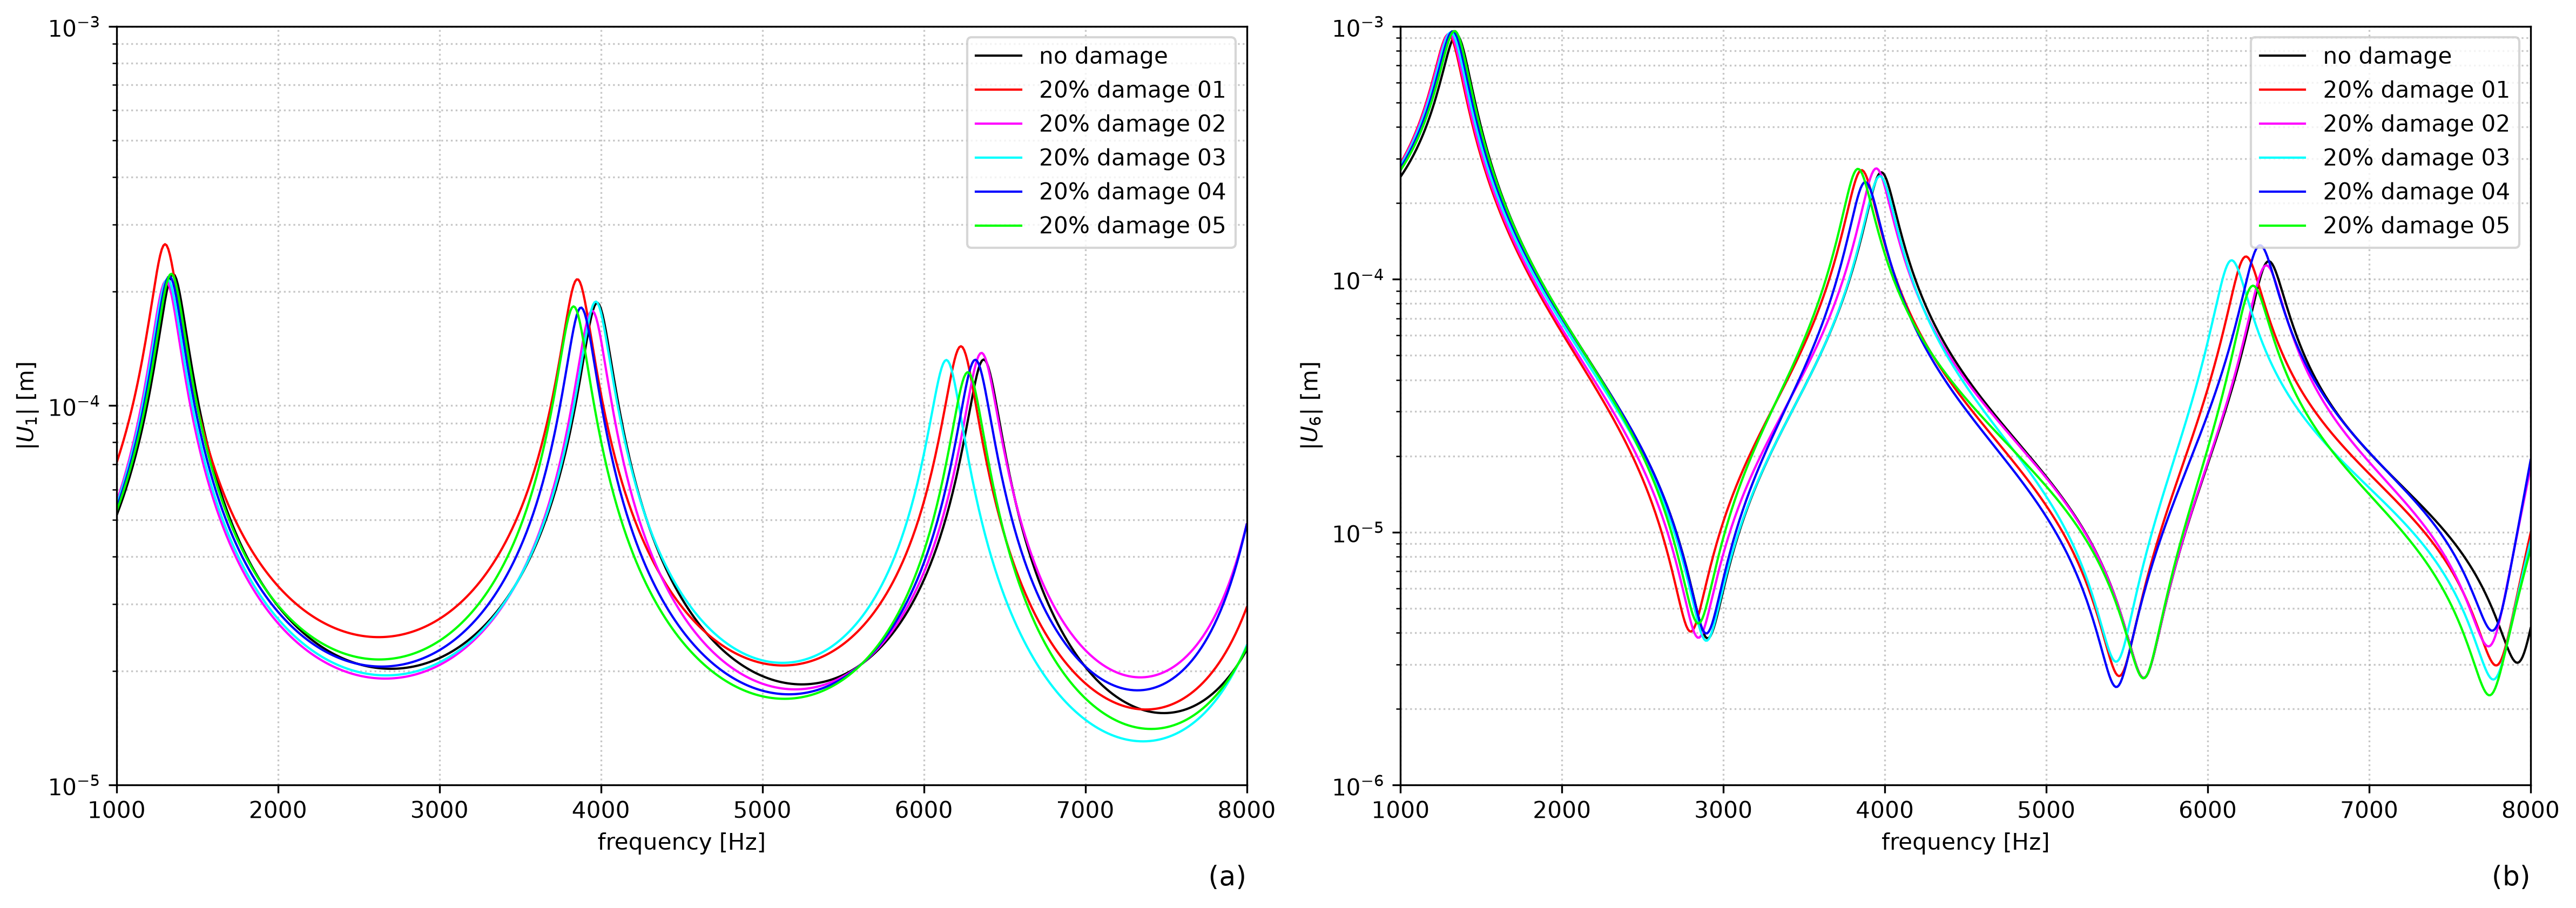

In [12]:
import numpy as np
import matplotlib.pyplot as plt
'''
# Parameters for the Computational Model
m = 0.3925
k = 4914e5
n_dof_cm = 6
force_magnitude = 10e3

# --- 2. Calculate Correct Damping Coefficients (α and β) ---
# This part is correct and remains the same.
f1, z1 = 1558, 0.060
f2, z2 = 3999, 0.024
w1, w2 = 2 * np.pi * f1, 2 * np.pi * f2
A = np.array([[1, w1**2], [1, w2**2]])
b = np.array([2 * z1 * w1, 2 * z2 * w2])
alpha_cm, beta_cm = 1e3 , 1e-7
'''
# Efficiently Assemble K Matrices for Each Damage Scenario

def assemble_stiffness_matrix(stiffness_values):
    """Assembles the global 6x6 stiffness matrix from a list of 6 spring stiffnesses."""
    K = np.zeros((n_dof_cm, n_dof_cm))

    # Spring 1: Connects wall to mass 1
    K[0, 0] += stiffness_values[0]

    # Springs 2-6: Connect mass (i-1) to mass i
    for i in range(1, n_dof_cm):
        ki = stiffness_values[i]
        # Add to diagonals
        K[i-1, i-1] += ki
        K[i, i]     += ki
        # Add to off-diagonals
        K[i-1, i] = -ki
        K[i, i-1] = -ki

    return K

damage_level = 0.20
k_damaged = k * (1 - damage_level)

k_matrices = []
model_names = ['no damage', '20% damage 01', '20% damage 02', '20% damage 03', '20% damage 04', '20% damage 05']

# Healthy Scenario
healthy_stiffnesses = [k] * 6
k_matrices.append(assemble_stiffness_matrix(healthy_stiffnesses))

# Damaged Scenarios
for i in range(5):
    damaged_stiffnesses = [k] * 6
    damaged_stiffnesses[i] = k_damaged
    k_matrices.append(assemble_stiffness_matrix(damaged_stiffnesses))

# Compute FRF for each scenario
#freq_range = np.linspace(1000, 8000, 2000)
omega_range = 2 * np.pi * freq_range

M_cm = m * np.eye(n_dof_cm)
f_cm = np.zeros(n_dof_cm)
f_cm[-1] = force_magnitude

responses_dof1 = []
responses_dof6 = []

for K_cm in k_matrices:
    C_cm = alpha_0 * M_cm + beta_0 * K_cm
    u_cm = np.zeros((n_dof_cm, len(omega_range)), dtype=complex)
    for i, omega in enumerate(omega_range):
        H = -omega**2 * M_cm + 1j * omega * C_cm + K_cm
        u_cm[:, i] = np.linalg.solve(H, f_cm)
    responses_dof1.append(np.abs(u_cm[0, :]))
    responses_dof6.append(np.abs(u_cm[5, :]))


# Plotting
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), dpi=300)
colors = ['black', 'red', 'magenta', 'cyan', 'blue', 'lime']

# Plot (a): Response at DOF #1
for i in range(len(model_names)):
    ax1.semilogy(freq_range, responses_dof1[i], label=model_names[i], color=colors[i], linewidth=1)
ax1.set_title('(a)', loc='right', y=-0.15)
ax1.set_xlabel('frequency [Hz]')
ax1.set_ylabel(r'$|U_1|$ [m]')
ax1.legend()
ax1.grid(True, which="both", linestyle=':', alpha=0.7)
ax1.set_xlim(1000, 8000)
ax1.set_ylim(1e-5, 1e-3)

# Plot (b): Response at DOF #6
for i in range(len(model_names)):
    ax2.semilogy(freq_range, responses_dof6[i], label=model_names[i], color=colors[i], linewidth=1)
ax2.set_title('(b)', loc='right', y=-0.15)
ax2.set_xlabel('frequency [Hz]')
ax2.set_ylabel(r'$|U_6|$ [m]')
ax2.legend()
ax2.grid(True, which="both", linestyle=':', alpha=0.7)
ax2.set_xlim(1000, 8000)
ax2.set_ylim(1e-6, 1e-3)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()


# Training Data generated with the stochastic digital twin with excitation frequency of 3800 Hz. Response at (a) DOF 1 and 6 (b) 2 and 4 (c) 3 and 5 (d) 5 and 6

# Damage = 20%

Generating 200 samples for 6 scenarios...
  Processing Scenario: healthy
  Processing Scenario: damage_s1
  Processing Scenario: damage_s2
  Processing Scenario: damage_s3
  Processing Scenario: damage_s4
  Processing Scenario: damage_s5

 Data generation completed successfully!
Dataset shape: (1200, 6)
 Dataset saved as 'digital_twin_dataset(20).csv'


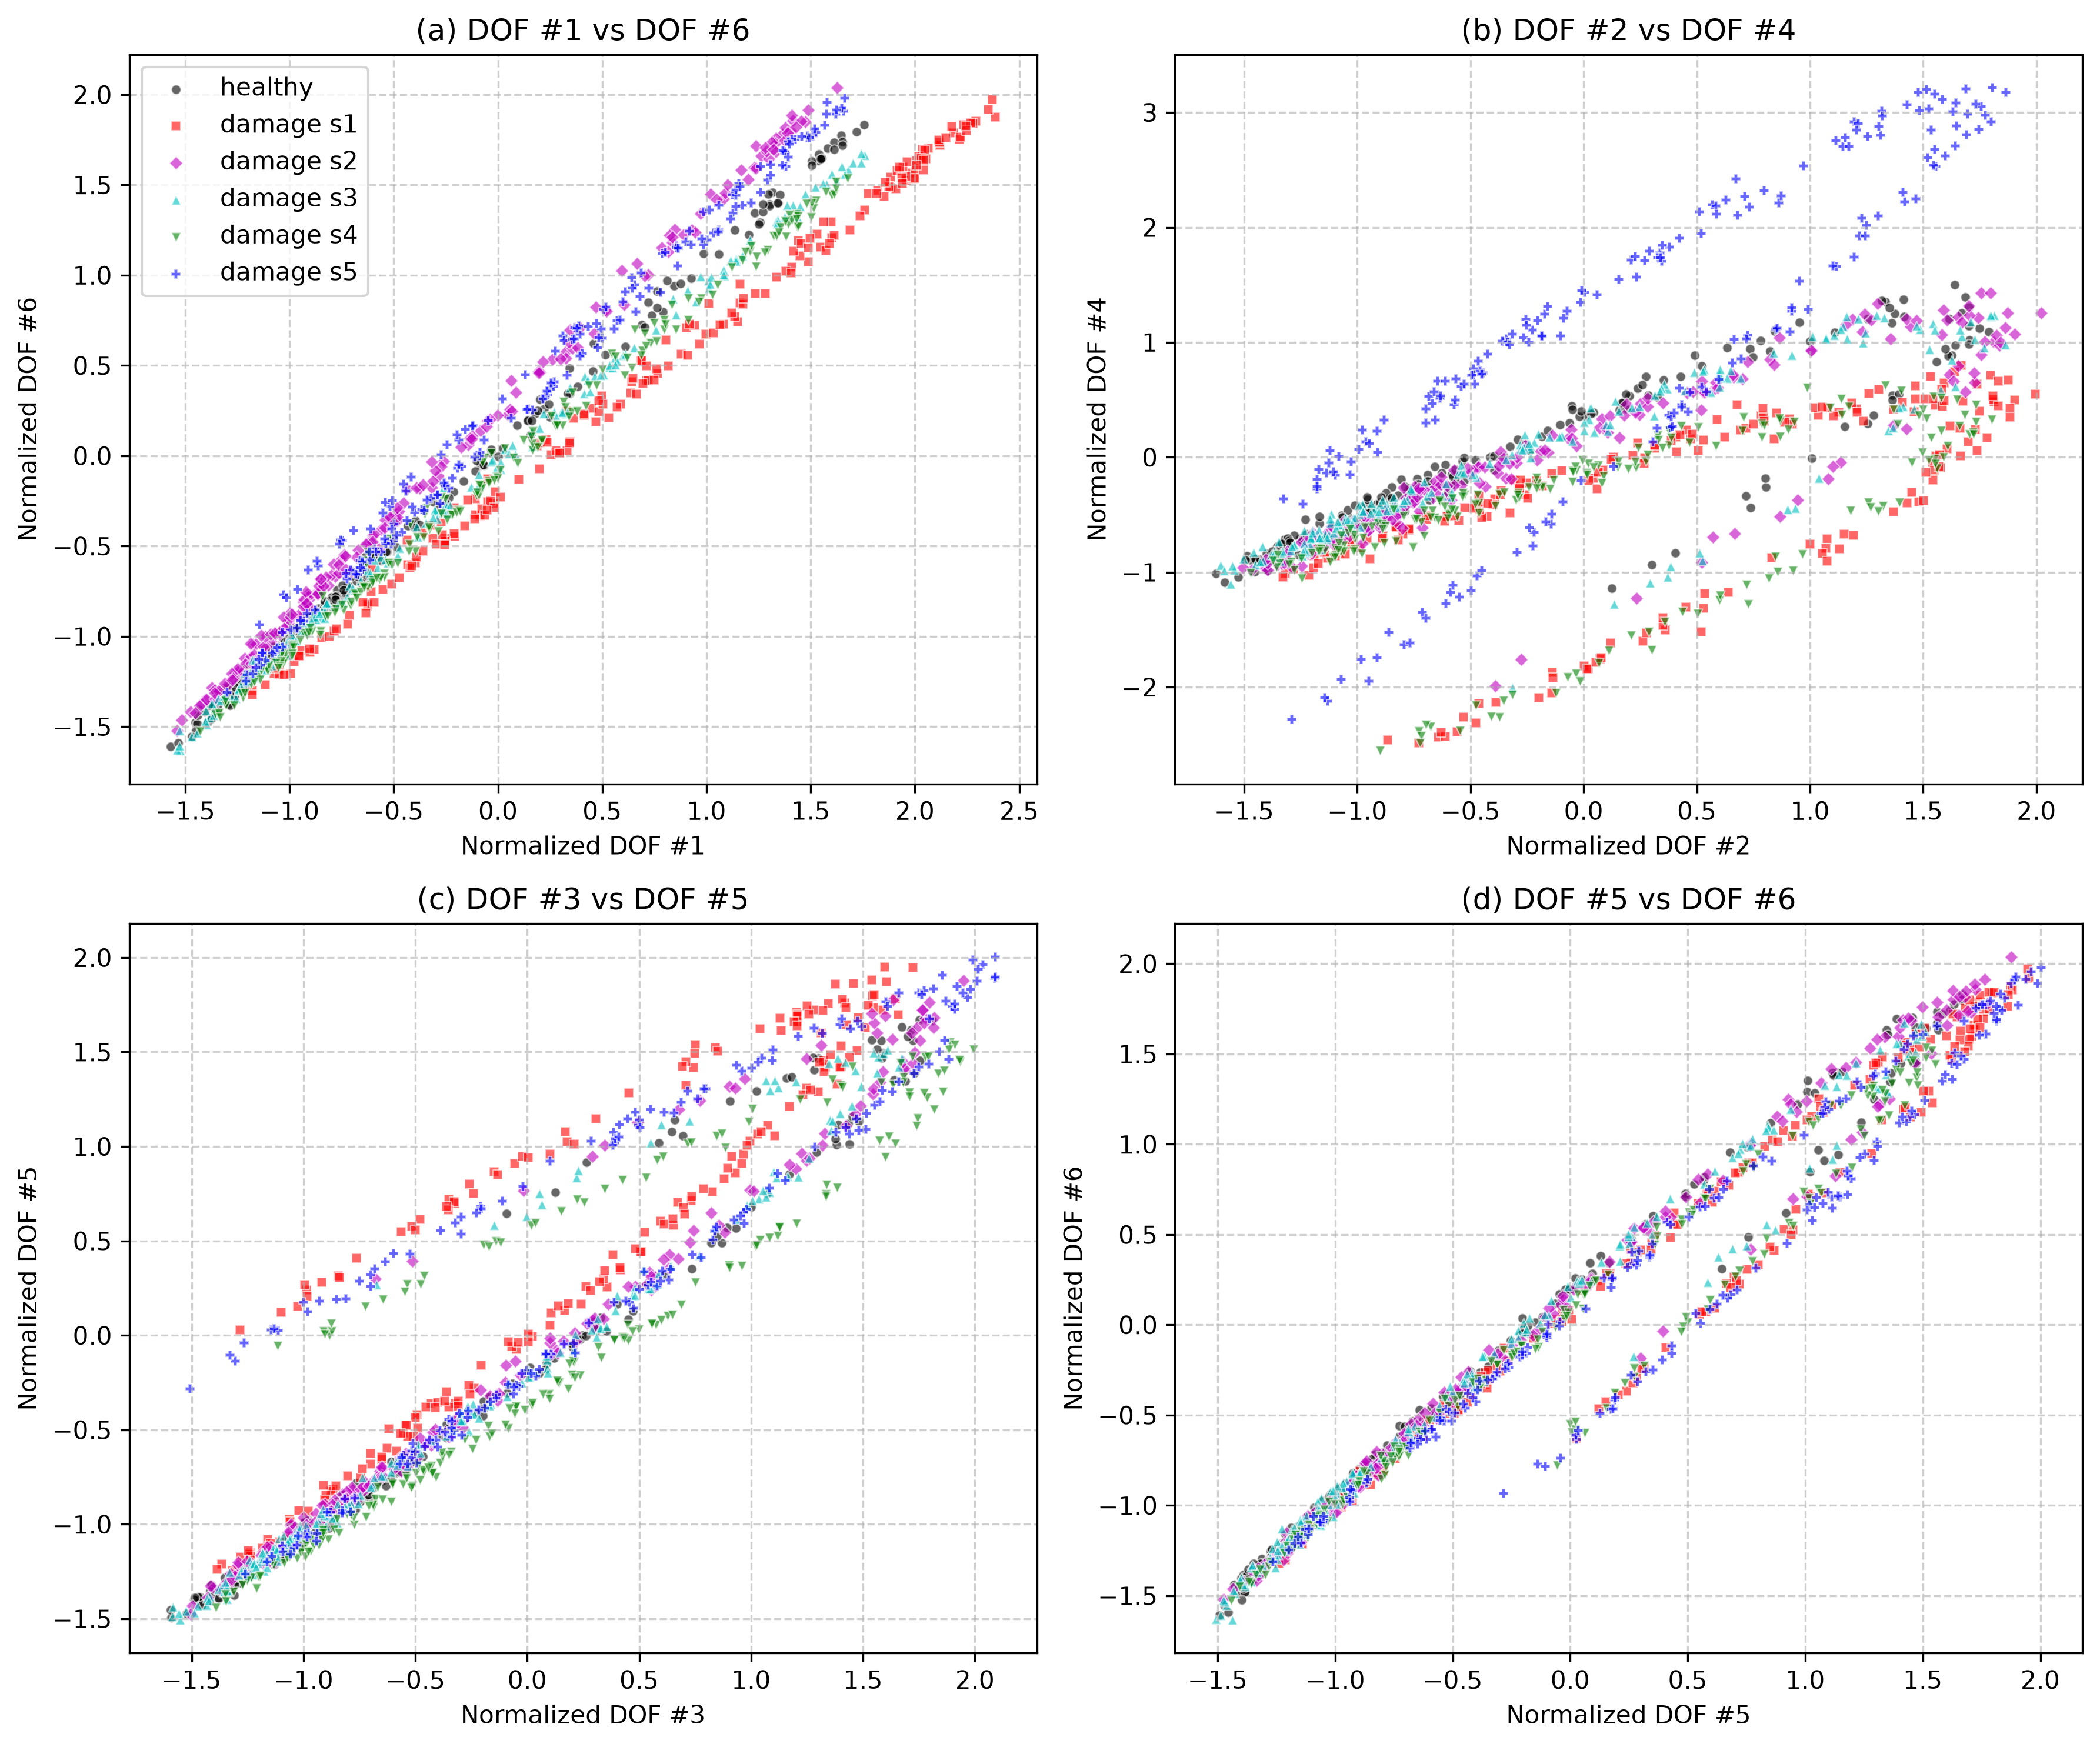


 QDA 5-fold Cross-Validation Accuracy: 94.75000% ± 1.43372%


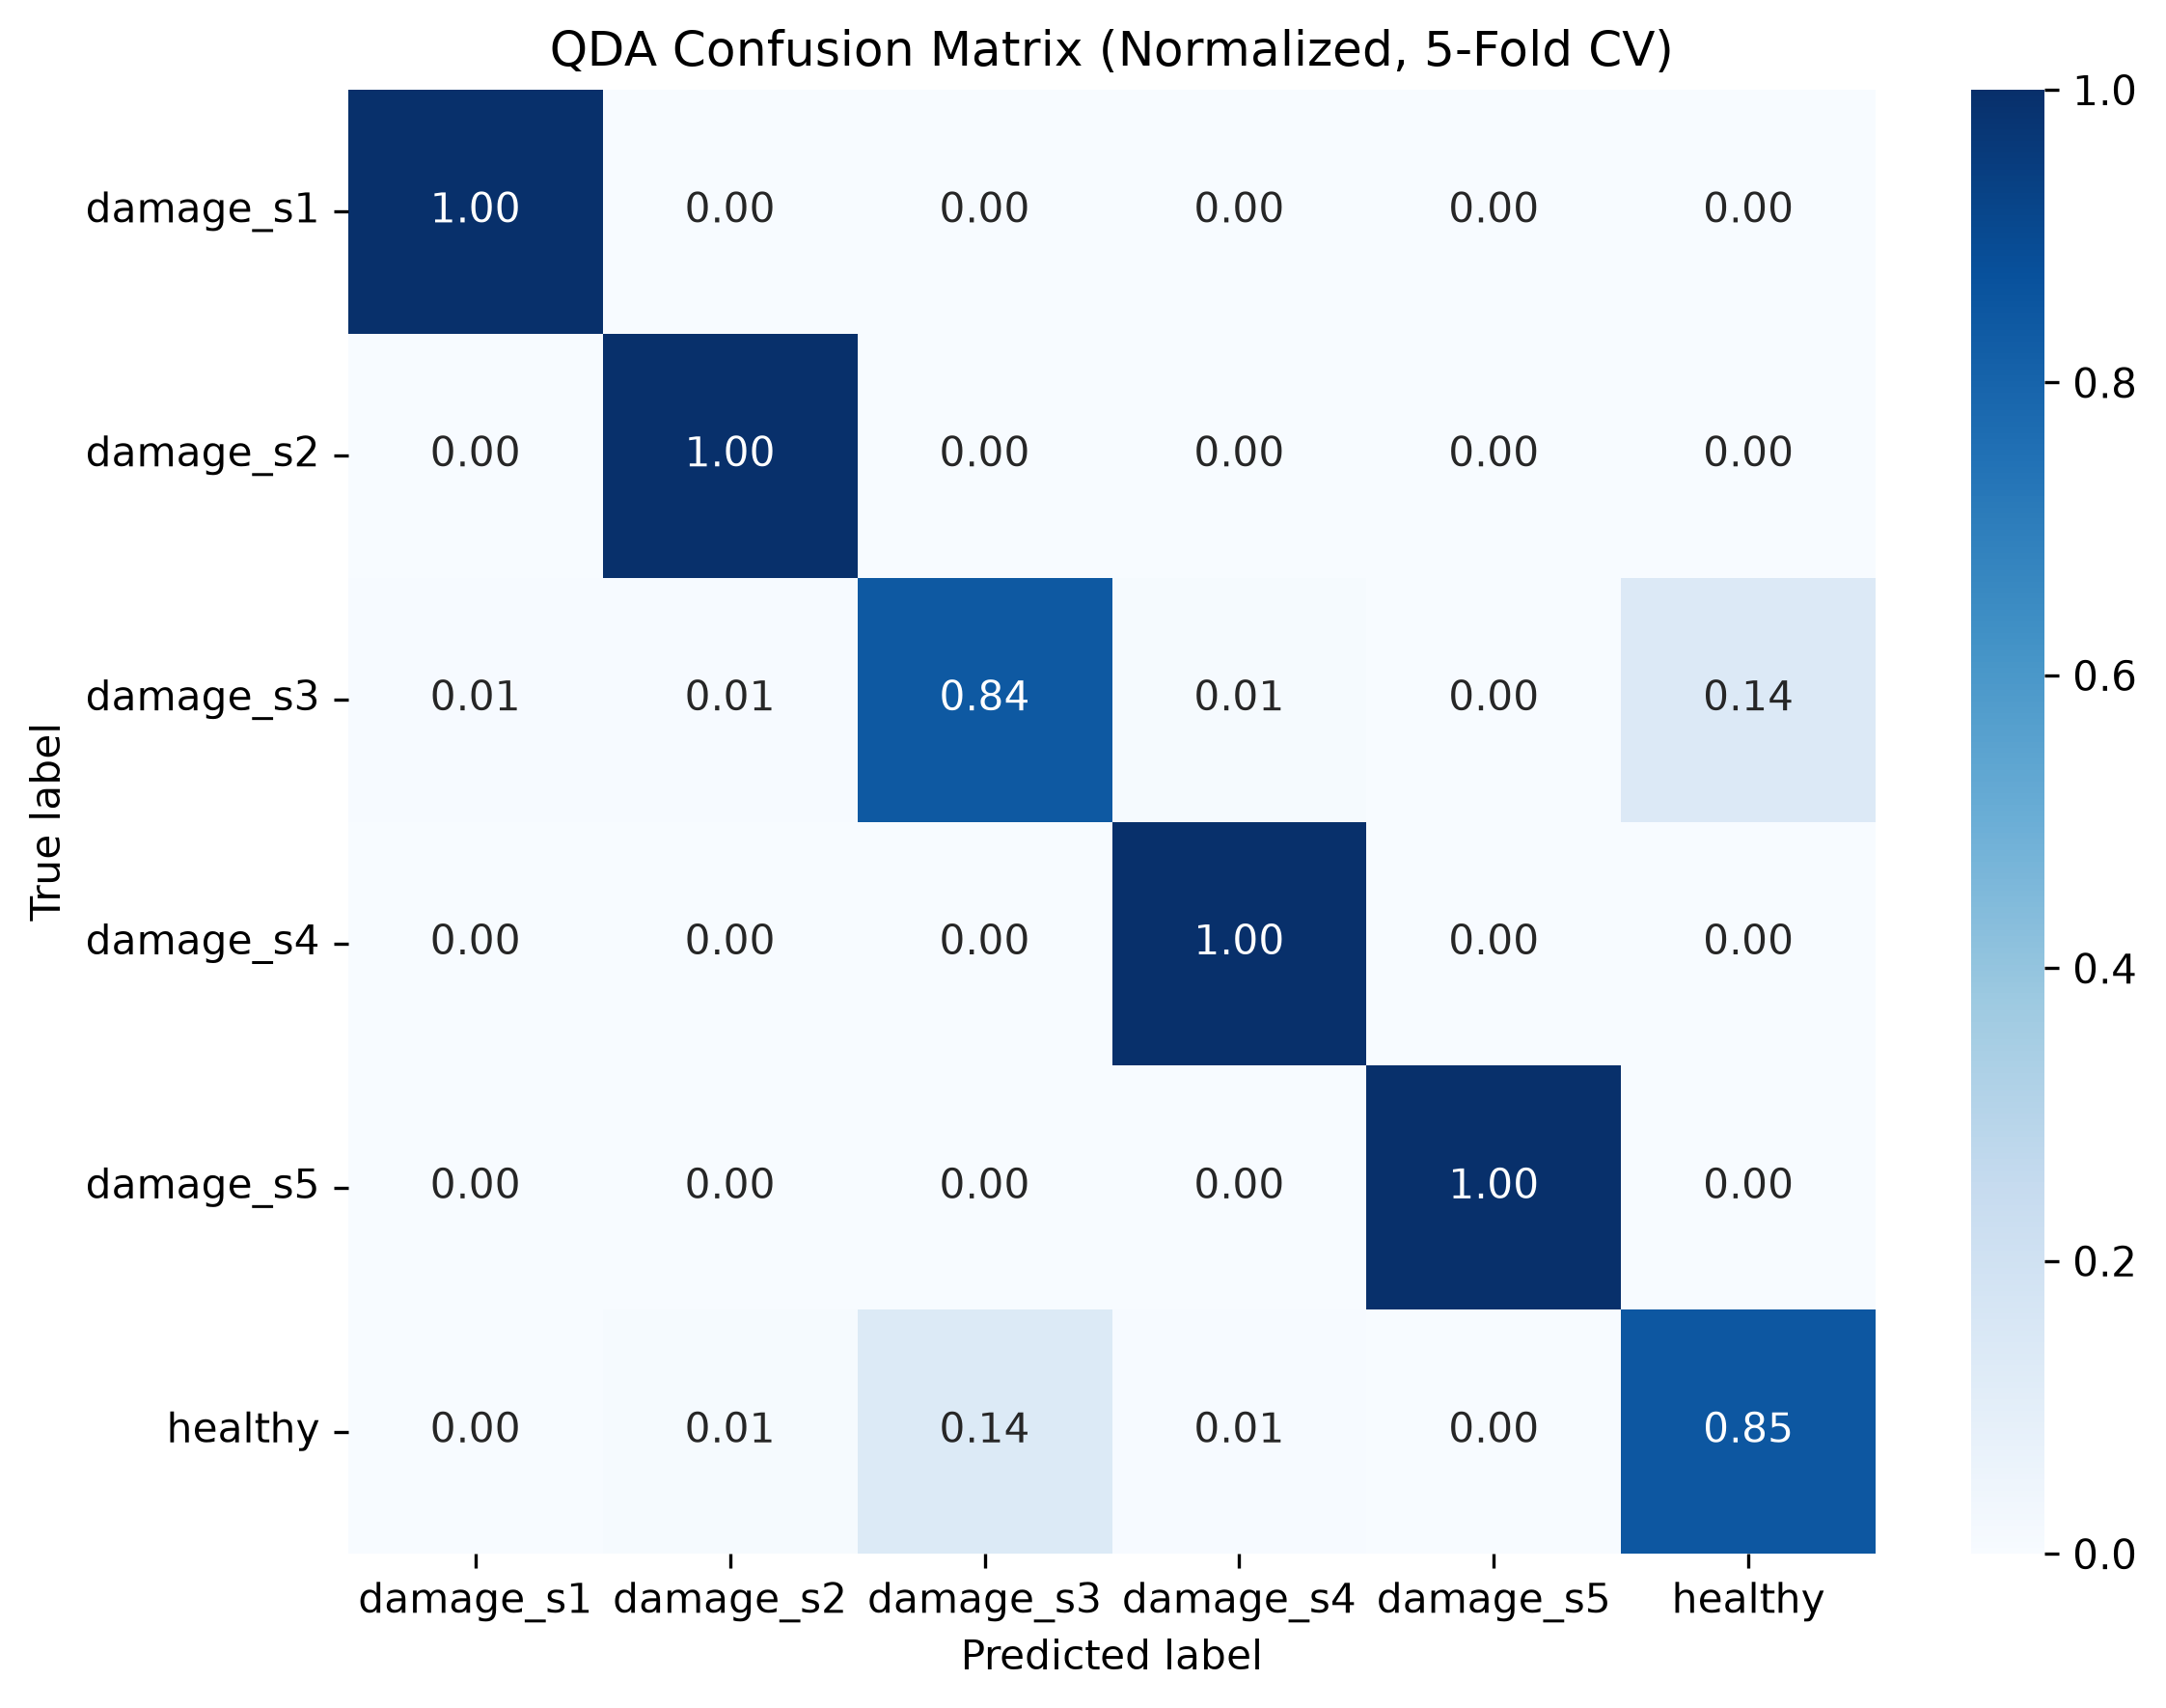

 Overall QDA accuracy (cross-validated): 94.83%
  damage_s1  → 100.0%
  damage_s2  → 100.0%
  damage_s3  → 84.0%
  damage_s4  → 100.0%
  damage_s5  → 100.0%
  healthy    → 85.0%


In [13]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split, cross_val_predict
from sklearn.metrics import confusion_matrix, accuracy_score

#   DATA GENERATION

m_nominal = 0.3925
k_nominal = 4914e5
n_dof_cm = 6
force_magnitude = 10e3

n_samples_per_scenario = 200
parameter_uncertainty = 0.05
freq_nominal = 3800
freq_uncertainty = 0.05
damage_nominal = 0.20
alpha_0, beta_0 = 1e3, 1e-7
sensor_noise_sigma = 10e-7

damage_locations = [0, 1, 2, 3, 4, 5]
dataset, labels = [], []

print(f"Generating {n_samples_per_scenario} samples for {len(damage_locations)} scenarios...")

for scen_idx, dmg_loc in enumerate(damage_locations):
    label = "healthy" if dmg_loc == 0 else f"damage_s{dmg_loc}"
    print(f"  Processing Scenario: {label}")

    scenario_samples = np.zeros((n_samples_per_scenario, n_dof_cm))

    for i in range(n_samples_per_scenario):
        m = m_nominal * np.random.uniform(1 - parameter_uncertainty, 1 + parameter_uncertainty)
        k = k_nominal * np.random.uniform(1 - parameter_uncertainty, 1 + parameter_uncertainty)
        freq = freq_nominal * np.random.uniform(1 - freq_uncertainty, 1 + freq_uncertainty)
        omega = 2 * np.pi * freq
        damage_actual = damage_nominal * np.random.uniform(0.95, 1.05)

        # Build stiffness matrix
        k_springs = np.full(n_dof_cm, k)
        if dmg_loc > 0:
            k_springs[dmg_loc - 1] *= (1 - damage_actual)

        M_cm = m * np.eye(n_dof_cm)
        K_cm = np.zeros((n_dof_cm, n_dof_cm))
        K_cm[0, 0] += k_springs[0]
        for j in range(1, n_dof_cm):
            K_cm[j-1:j+1, j-1:j+1] += k_springs[j] * np.array([[1, -1], [-1, 1]])
        C_cm = alpha_0 * M_cm + beta_0 * K_cm

        f_cm = np.zeros((n_dof_cm, 1))
        f_cm[-1] = force_magnitude
        H = np.linalg.inv(-omega**2 * M_cm + 1j * omega * C_cm + K_cm)
        u_cm = (H @ f_cm).flatten()

        # Add Gaussian noise
        u_mag_noisy = np.abs(u_cm) + np.random.normal(0, sensor_noise_sigma, n_dof_cm)
        u_mag_noisy = np.maximum(u_mag_noisy, 0)
        scenario_samples[i, :] = u_mag_noisy

    dataset.append(scenario_samples)
    labels.extend([label] * n_samples_per_scenario)

X_data = np.vstack(dataset)
X_mean, X_std = np.mean(X_data, axis=0), np.std(X_data, axis=0)
X_normalized = (X_data - X_mean) / X_std

print("\n Data generation completed successfully!")
print("Dataset shape:", X_normalized.shape)


#  SAVE DATASET (for reuse)

columns = [f"DOF_{i+1}" for i in range(n_dof_cm)]
df = pd.DataFrame(X_normalized, columns=columns)
df["label"] = labels
csv_filename = "digital_twin_dataset(20).csv"
df.to_csv(csv_filename, index=False)
print(f" Dataset saved as '{csv_filename}'")


#  VISUALIZATION

fig, axes = plt.subplots(2, 2, figsize=(12, 10), dpi=300)
axes = axes.flatten()
plot_titles = [
    '(a) DOF #1 vs DOF #6',
    '(b) DOF #2 vs DOF #4',
    '(c) DOF #3 vs DOF #5',
    '(d) DOF #5 vs DOF #6',
]
plot_dofs = [(0, 5), (1, 3), (2, 4), (4, 5)]
colors = ['k', 'r', 'm', 'c', 'g', 'b']
markers = ['o', 's', 'D', '^', 'v', 'P']
legend_labels = ['healthy', 'damage s1', 'damage s2', 'damage s3', 'damage s4', 'damage s5']

for i, ax in enumerate(axes):
    x_dof, y_dof = plot_dofs[i]
    for scen_idx in range(len(damage_locations)):
        start = scen_idx * n_samples_per_scenario
        end = start + n_samples_per_scenario
        ax.scatter(X_normalized[start:end, x_dof],
                   X_normalized[start:end, y_dof],
                   c=colors[scen_idx], marker=markers[scen_idx],
                   s=15, alpha=0.6, label=legend_labels[scen_idx],
                   edgecolors='w', linewidth=0.5)
    ax.set_xlabel(f'Normalized DOF #{x_dof+1}')
    ax.set_ylabel(f'Normalized DOF #{y_dof+1}')
    ax.set_title(plot_titles[i])
    ax.grid(True, linestyle='--', alpha=0.6)
    if i == 0:
        ax.legend()

plt.tight_layout()
plt.show()


#  QDA CLASSIFICATION

y_labels = np.array(labels)
qda = QuadraticDiscriminantAnalysis(store_covariance=True)

# 5-fold cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True)
cv_scores = cross_val_score(qda, X_normalized, y_labels, cv=cv, scoring='accuracy')
print(f"\n QDA 5-fold Cross-Validation Accuracy: {np.mean(cv_scores)*100:.5f}% ± {np.std(cv_scores)*100:.5f}%")

# Cross-validated confusion matrix (aggregated predictions)
y_pred_cv = cross_val_predict(qda, X_normalized, y_labels, cv=5)
cm = confusion_matrix(y_labels, y_pred_cv, labels=np.unique(y_labels))
cm_norm = cm / cm.sum(axis=1, keepdims=True)

# Plot confusion matrix (normalized)
plt.figure(figsize=(8,6), dpi=300)
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=np.unique(y_labels),
            yticklabels=np.unique(y_labels))
plt.title("QDA Confusion Matrix (Normalized, 5-Fold CV)")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.tight_layout()
plt.show()

# Overall accuracy (same as CV mean)
overall_acc = accuracy_score(y_labels, y_pred_cv)
print(f" Overall QDA accuracy (cross-validated): {overall_acc*100:.2f}%")

# Show class-wise accuracy
class_acc = np.diag(cm_norm)
for lbl, acc in zip(np.unique(y_labels), class_acc):
    print(f"  {lbl:10s} → {acc*100:.1f}%")


# Damage = 10%

Generating 200 samples for 6 scenarios...
  Processing Scenario: healthy
  Processing Scenario: damage_s1
  Processing Scenario: damage_s2
  Processing Scenario: damage_s3
  Processing Scenario: damage_s4
  Processing Scenario: damage_s5

 Data generation completed successfully!
Dataset shape: (1200, 6)
 Dataset saved as 'digital_twin_dataset.csv'


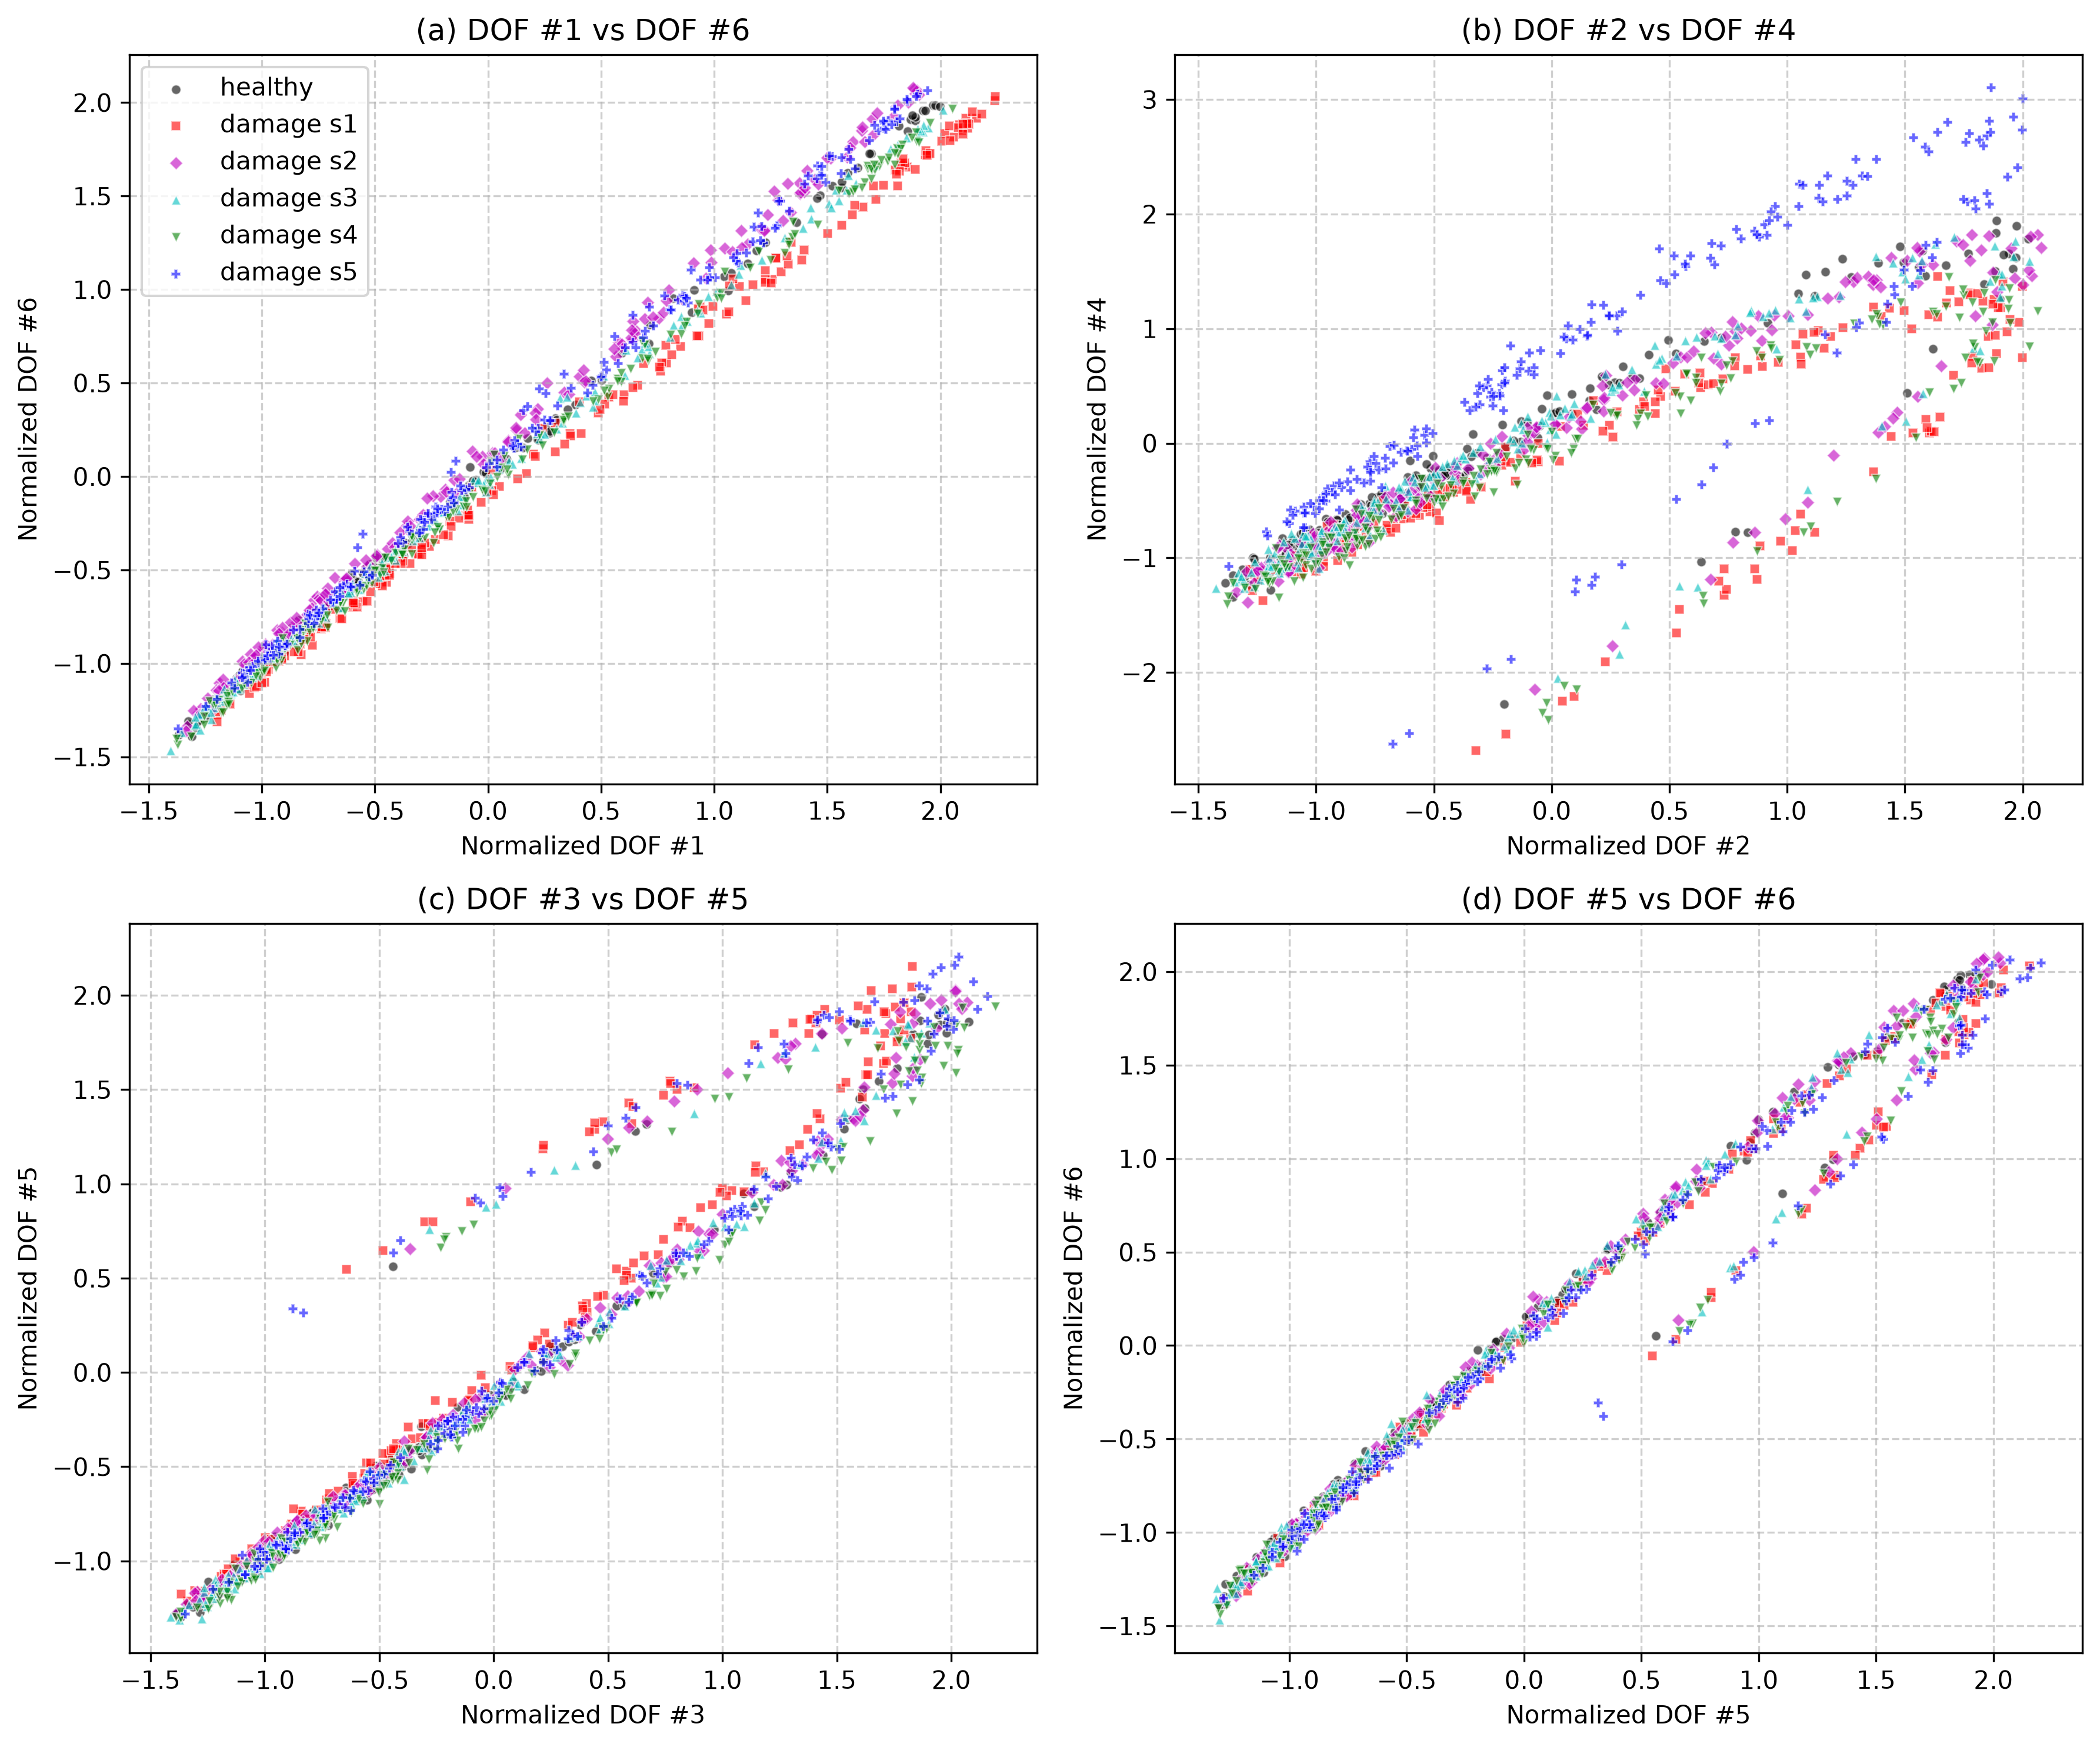


 QDA 5-fold Cross-Validation Accuracy: 83.16667% ± 2.95334%


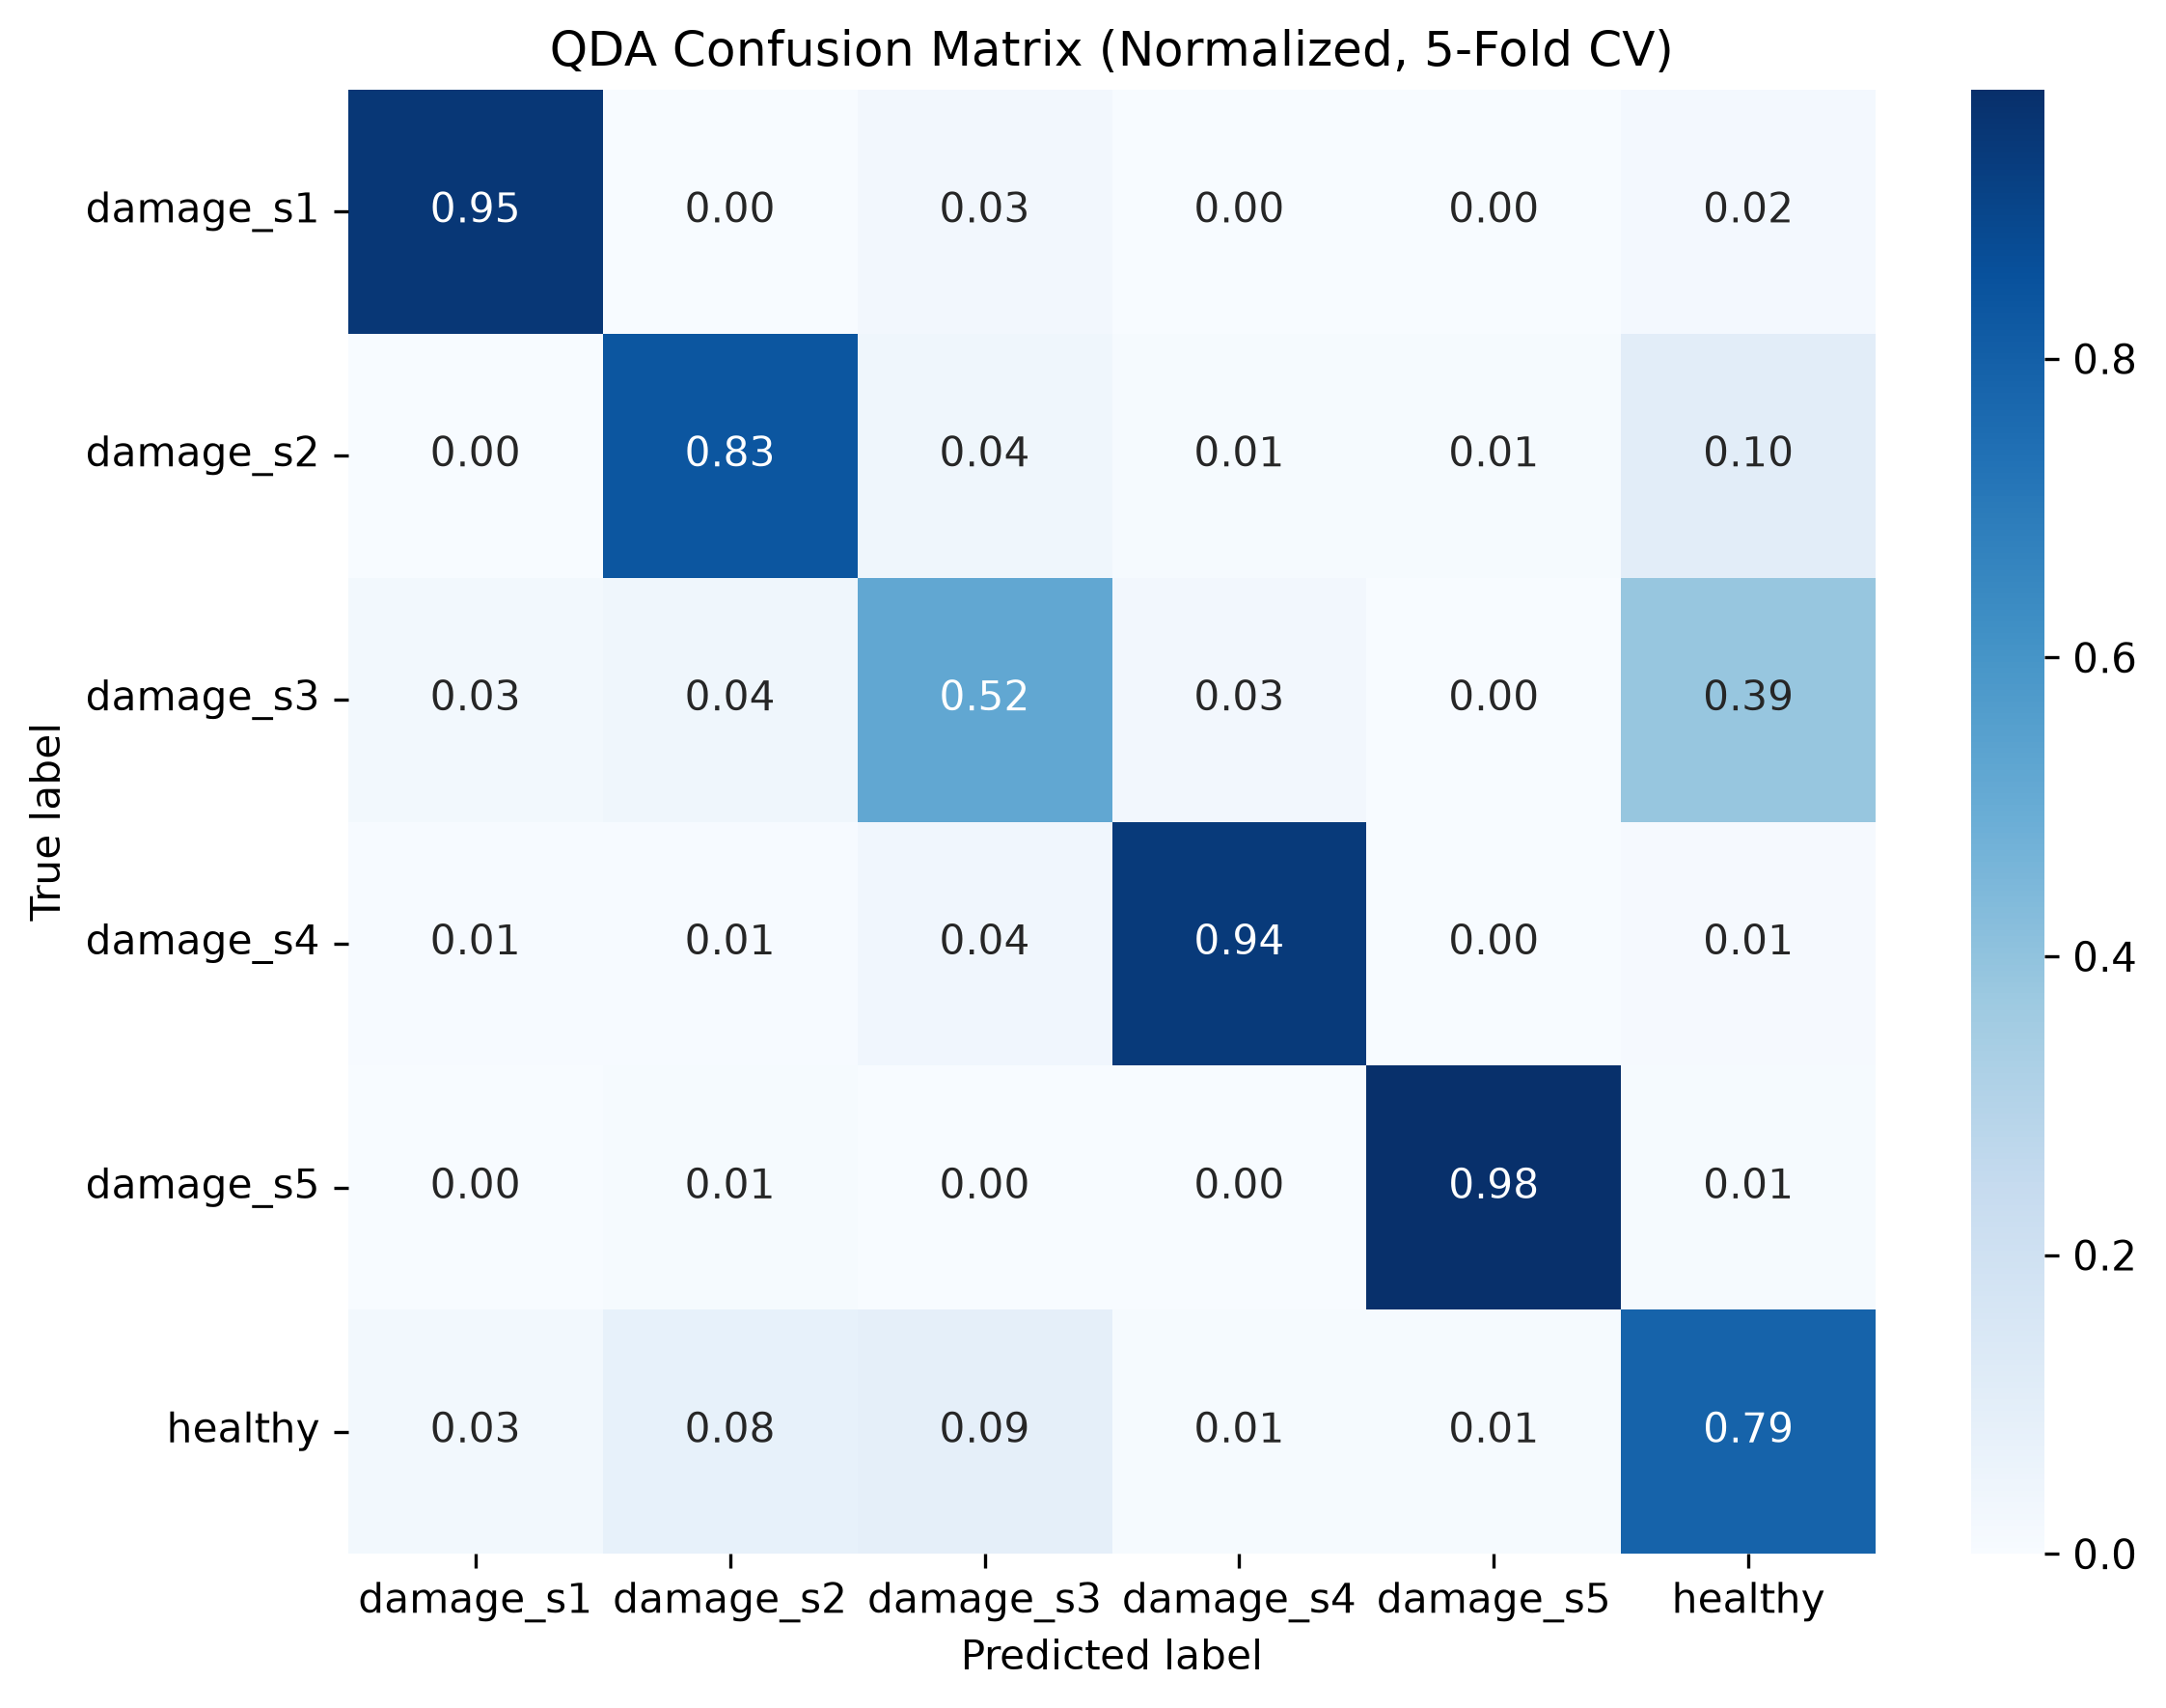

Overall QDA accuracy (cross-validated): 83.50%
  damage_s1  → 95.0%
  damage_s2  → 83.5%
  damage_s3  → 52.0%
  damage_s4  → 94.0%
  damage_s5  → 98.0%
  healthy    → 78.5%


In [14]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split, cross_val_predict
from sklearn.metrics import confusion_matrix, accuracy_score

#   DATA GENERATION

m_nominal = 0.3925
k_nominal = 4914e5
n_dof_cm = 6
force_magnitude = 10e3

n_samples_per_scenario = 200
parameter_uncertainty = 0.05
freq_nominal = 3800
freq_uncertainty = 0.05
damage_nominal = 0.10
alpha_0, beta_0 = 1e3, 1e-7
sensor_noise_sigma = 10e-7

damage_locations = [0, 1, 2, 3, 4, 5]
dataset, labels = [], []

print(f"Generating {n_samples_per_scenario} samples for {len(damage_locations)} scenarios...")

for scen_idx, dmg_loc in enumerate(damage_locations):
    label = "healthy" if dmg_loc == 0 else f"damage_s{dmg_loc}"
    print(f"  Processing Scenario: {label}")

    scenario_samples = np.zeros((n_samples_per_scenario, n_dof_cm))

    for i in range(n_samples_per_scenario):
        m = m_nominal * np.random.uniform(1 - parameter_uncertainty, 1 + parameter_uncertainty)
        k = k_nominal * np.random.uniform(1 - parameter_uncertainty, 1 + parameter_uncertainty)
        freq = freq_nominal * np.random.uniform(1 - freq_uncertainty, 1 + freq_uncertainty)
        omega = 2 * np.pi * freq
        damage_actual = damage_nominal * np.random.uniform(0.95, 1.05)

        # Build stiffness matrix
        k_springs = np.full(n_dof_cm, k)
        if dmg_loc > 0:
            k_springs[dmg_loc - 1] *= (1 - damage_actual)

        M_cm = m * np.eye(n_dof_cm)
        K_cm = np.zeros((n_dof_cm, n_dof_cm))
        K_cm[0, 0] += k_springs[0]
        for j in range(1, n_dof_cm):
            K_cm[j-1:j+1, j-1:j+1] += k_springs[j] * np.array([[1, -1], [-1, 1]])
        C_cm = alpha_0 * M_cm + beta_0 * K_cm

        f_cm = np.zeros((n_dof_cm, 1))
        f_cm[-1] = force_magnitude
        H = np.linalg.inv(-omega**2 * M_cm + 1j * omega * C_cm + K_cm)
        u_cm = (H @ f_cm).flatten()

        # Add Gaussian noise
        u_mag_noisy = np.abs(u_cm) + np.random.normal(0, sensor_noise_sigma, n_dof_cm)
        u_mag_noisy = np.maximum(u_mag_noisy, 0)
        scenario_samples[i, :] = u_mag_noisy

    dataset.append(scenario_samples)
    labels.extend([label] * n_samples_per_scenario)

X_data = np.vstack(dataset)
X_mean, X_std = np.mean(X_data, axis=0), np.std(X_data, axis=0)
X_normalized = (X_data - X_mean) / X_std

print("\n Data generation completed successfully!")
print("Dataset shape:", X_normalized.shape)


#  SAVE DATASET

columns = [f"DOF_{i+1}" for i in range(n_dof_cm)]
df = pd.DataFrame(X_normalized, columns=columns)
df["label"] = labels
csv_filename = "digital_twin_dataset.csv"
df.to_csv(csv_filename, index=False)
print(f" Dataset saved as '{csv_filename}'")


#   VISUALIZATION
fig, axes = plt.subplots(2, 2, figsize=(12, 10), dpi=300)
axes = axes.flatten()
plot_titles = [
    '(a) DOF #1 vs DOF #6',
    '(b) DOF #2 vs DOF #4',
    '(c) DOF #3 vs DOF #5',
    '(d) DOF #5 vs DOF #6',
]
plot_dofs = [(0, 5), (1, 3), (2, 4), (4, 5)]
colors = ['k', 'r', 'm', 'c', 'g', 'b']
markers = ['o', 's', 'D', '^', 'v', 'P']
legend_labels = ['healthy', 'damage s1', 'damage s2', 'damage s3', 'damage s4', 'damage s5']

for i, ax in enumerate(axes):
    x_dof, y_dof = plot_dofs[i]
    for scen_idx in range(len(damage_locations)):
        start = scen_idx * n_samples_per_scenario
        end = start + n_samples_per_scenario
        ax.scatter(X_normalized[start:end, x_dof],
                   X_normalized[start:end, y_dof],
                   c=colors[scen_idx], marker=markers[scen_idx],
                   s=15, alpha=0.6, label=legend_labels[scen_idx],
                   edgecolors='w', linewidth=0.5)
    ax.set_xlabel(f'Normalized DOF #{x_dof+1}')
    ax.set_ylabel(f'Normalized DOF #{y_dof+1}')
    ax.set_title(plot_titles[i])
    ax.grid(True, linestyle='--', alpha=0.6)
    if i == 0:
        ax.legend()

plt.tight_layout()
plt.show()


# QDA CLASSIFICATION (Section 4.6)

y_labels = np.array(labels)
qda = QuadraticDiscriminantAnalysis(store_covariance=True)

# 5-fold cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True)
cv_scores = cross_val_score(qda, X_normalized, y_labels, cv=cv, scoring='accuracy')
print(f"\n QDA 5-fold Cross-Validation Accuracy: {np.mean(cv_scores)*100:.5f}% ± {np.std(cv_scores)*100:.5f}%")

# Cross-validated confusion matrix (aggregated predictions)
y_pred_cv = cross_val_predict(qda, X_normalized, y_labels, cv=5)
cm = confusion_matrix(y_labels, y_pred_cv, labels=np.unique(y_labels))
cm_norm = cm / cm.sum(axis=1, keepdims=True)

# Plot confusion matrix (normalized)
plt.figure(figsize=(8,6), dpi=300)
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=np.unique(y_labels),
            yticklabels=np.unique(y_labels))
plt.title("QDA Confusion Matrix (Normalized, 5-Fold CV)")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.tight_layout()
plt.show()

# Overall accuracy (same as CV mean)
overall_acc = accuracy_score(y_labels, y_pred_cv)
print(f"Overall QDA accuracy (cross-validated): {overall_acc*100:.2f}%")

# Show class-wise accuracy
class_acc = np.diag(cm_norm)
for lbl, acc in zip(np.unique(y_labels), class_acc):
    print(f"  {lbl:10s} → {acc*100:.1f}%")


# Adding more noise

In [15]:
import numpy as np, pandas as pd
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.model_selection import StratifiedKFold, cross_val_score

# --- Model parameters (same as reference) ---
m_nominal, k_nominal = 0.3925, 4914e5
n_dof, alpha_0, beta_0 = 6, 1e3, 1e-7
force_magnitude = 1e4
freq_nominal = 3800
freq_uncertainty, parameter_uncertainty = 0.05, 0.05
damage_nominal, n_samples = 0.2, 200
sensor_noise_sigma = 2e-6  # doubled noise (2σ)
damage_locations = [0,1,2,3,4,5]

# --- Data generation ---
dataset, labels = [], []
for loc in damage_locations:
    lbl = "healthy" if loc==0 else f"damage_s{loc}"
    samples = np.zeros((n_samples, n_dof))
    for i in range(n_samples):
        m = m_nominal*np.random.uniform(0.95,1.05)
        k = k_nominal*np.random.uniform(0.95,1.05)
        freq = freq_nominal*np.random.uniform(0.95,1.05)
        omega = 2*np.pi*freq
        dmg = damage_nominal*np.random.uniform(0.95,1.05)
        k_spr = np.full(n_dof,k)
        if loc>0: k_spr[loc-1]*=(1-dmg)

        M = m*np.eye(n_dof)
        K = np.zeros((n_dof,n_dof))
        K[0,0]+=k_spr[0]
        for j in range(1,n_dof):
            K[j-1:j+1,j-1:j+1]+=k_spr[j]*np.array([[1,-1],[-1,1]])
        C = alpha_0*M + beta_0*K

        f = np.zeros((n_dof,1)); f[-1]=force_magnitude
        H = np.linalg.inv(-omega**2*M + 1j*omega*C + K)
        u = np.abs((H@f).flatten()) + np.random.normal(0,sensor_noise_sigma,n_dof)
        samples[i,:]=np.maximum(u,0)
    dataset.append(samples); labels += [lbl]*n_samples

X = np.vstack(dataset); X=(X-X.mean(0))/X.std(0); y=np.array(labels)

# --- QDA evaluation ---
qda=QuadraticDiscriminantAnalysis(store_covariance=True)
cv=StratifiedKFold(n_splits=5,shuffle=True)
acc=np.mean(cross_val_score(qda,X,y,cv=cv,scoring="accuracy"))
print(f" More Noise (2σ) Accuracy: {acc*100:.2f}%")


 More Noise (2σ) Accuracy: 88.25%


# different excitation frequency

In [16]:
import numpy as np, pandas as pd
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.model_selection import StratifiedKFold, cross_val_score

m_nominal,k_nominal=0.3925,4914e5
n_dof,alpha_0,beta_0=6,1e3,1e-7
force_magnitude=1e4
freq_nominal=7000            # changed frequency
freq_uncertainty=0.05
parameter_uncertainty=0.05
damage_nominal=0.2
sensor_noise_sigma=1e-6
n_samples=200
damage_locations=[0,1,2,3,4,5]

dataset,labels=[],[]
for loc in damage_locations:
    lbl="healthy" if loc==0 else f"damage_s{loc}"
    samples=np.zeros((n_samples,n_dof))
    for i in range(n_samples):
        m=m_nominal*np.random.uniform(0.95,1.05)
        k=k_nominal*np.random.uniform(0.95,1.05)
        freq=freq_nominal*np.random.uniform(0.95,1.05)
        omega=2*np.pi*freq
        dmg=damage_nominal*np.random.uniform(0.95,1.05)
        k_spr=np.full(n_dof,k)
        if loc>0: k_spr[loc-1]*=(1-dmg)
        M=m*np.eye(n_dof)
        K=np.zeros((n_dof,n_dof))
        K[0,0]+=k_spr[0]
        for j in range(1,n_dof):
            K[j-1:j+1,j-1:j+1]+=k_spr[j]*np.array([[1,-1],[-1,1]])
        C=alpha_0*M+beta_0*K
        f=np.zeros((n_dof,1)); f[-1]=force_magnitude
        H=np.linalg.inv(-omega**2*M+1j*omega*C+K)
        u=np.abs((H@f).flatten())+np.random.normal(0,sensor_noise_sigma,n_dof)
        samples[i,:]=np.maximum(u,0)
    dataset.append(samples); labels+=[lbl]*n_samples

X=np.vstack(dataset); X=(X-X.mean(0))/X.std(0); y=np.array(labels)
qda=QuadraticDiscriminantAnalysis(store_covariance=True)
cv=StratifiedKFold(n_splits=5,shuffle=True)
acc=np.mean(cross_val_score(qda,X,y,cv=cv,scoring="accuracy"))
print(f" Different Excitation Frequency (7000 Hz) Accuracy: {acc*100:.2f}%")


 Different Excitation Frequency (7000 Hz) Accuracy: 77.08%


# different force location

In [17]:
import numpy as np
import pandas as pd
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.model_selection import StratifiedKFold, cross_val_score

df = pd.read_csv("digital_twin_dataset(20).csv")
print(f"Loaded dataset: {df.shape[0]} samples, {df.shape[1]-1} features")

X_full = df.drop("label", axis=1).values
y_full = df["label"].values
all_dofs = [col for col in df.columns if col.startswith("DOF_")]

# ------------------------------------------------------------
# compute 5-fold QDA accuracy for any dataset subset

def qda_accuracy(X, y):
    qda = QuadraticDiscriminantAnalysis(store_covariance=True)
    cv = StratifiedKFold(n_splits=5, shuffle=True)
    return np.mean(cross_val_score(qda, X, y, cv=cv, scoring="accuracy")) * 100

# Case : Less sensors
X_less = X_full[:, 1:]
less_sensor_acc = qda_accuracy(X_less, y_full)


# Case : More uncertainty (±10%)
scale = np.random.uniform(0.9, 1.1, X_full.shape)
X_unc = (X_full * scale - (X_full * scale).mean(0)) / (X_full * scale).std(0)
more_uncert_acc = qda_accuracy(X_unc, y_full)
results = [

    ("Less sensors (2–6)", less_sensor_acc),

    ("More uncertainty (±10%)", more_uncert_acc),
]

df_results = pd.DataFrame(results, columns=["Case", "Accuracy (%)"])

print(df_results.to_string(index=False))


Loaded dataset: 1200 samples, 6 features
                   Case  Accuracy (%)
     Less sensors (2–6)     77.916667
More uncertainty (±10%)     80.916667
